In [4]:
!pip install -q -U ultralytics roboflow


In [5]:
from google.colab import userdata
from roboflow import Roboflow

from pathlib import Path
import yaml

import cv2, random
import numpy as np
import matplotlib.pyplot as plt
from glob import glob

from ultralytics import YOLO
from IPython.display import display , Image


In [6]:
# Download the dataset from Roboflow

api_key = userdata.get("ROBOFLOW_API_KEY")  # must match the secret name exactly
rf = Roboflow(api_key=api_key)
project = rf.workspace("hust-ajpvu").project("food-srnub")
dataset = project.version(1).download("yolov8")

print("Dataset location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to food-1 in yolov8:: 100%|██████████| 18312/18312 [00:02<00:00, 7043.48it/s]


Dataset location: /content/food-1


# Explor Data And Classes

In [7]:


ROOT = Path(dataset.location)
print("ROOT:", ROOT)

print("\nContent:")
for p in sorted(ROOT.iterdir()):
    print(" ", "[dir] " if p.is_dir() else "[file]", p.name)

print('\nNumber Of Files')
for split in ["train", "valid", "test"]:
    imgs = ROOT / split / "images"
    lbls = ROOT / split / "labels"
    n_img = len(list(imgs.glob("*"))) if imgs.exists() else 0
    n_lbl = len(list(lbls.glob("*.txt"))) if lbls.exists() else 0
    print(f"  {split:6s} images={n_img:5d}  labels={n_lbl:5d}")

print("\ndata.yaml:")
print((ROOT / "data.yaml").read_text())

ROOT: /content/food-1

Content:
  [file] README.dataset.txt
  [file] README.roboflow.txt
  [file] data.yaml
  [dir]  test
  [dir]  train
  [dir]  valid

Number Of Files
  train  images= 6404  labels= 6404
  valid  images= 1830  labels= 1830
  test   images=  916  labels=  916

data.yaml:
names:
- apple
- avocado
- banana
- bread-white
- bread-wholemeal
- broccoli
- butter
- carrot
- cheese
- chicken
- coffee-with-caffeine
- cucumber
- egg
- espresso-with-caffeine
- hard-cheese
- jam
- mixed-salad-chopped-without-sauce
- mixed-vegetables
- pasta-spaghetti
- potatoes-steamed
- rice
- salad-leaf-salad-green
- sweet-pepper
- tea
- tomato
- tomato-sauce
- water
- white-coffee-with-caffeine
- wine-red
- wine-white
nc: 30
roboflow:
  license: CC BY 4.0
  project: food-srnub
  url: https://universe.roboflow.com/hust-ajpvu/food-srnub/dataset/1
  version: 1
  workspace: hust-ajpvu
test: ../test/images
train: ../train/images
val: ../valid/images



# Display Random Images

In [8]:

def show_samples(root="/content/food-1", split="train", rows=3, cols=3, size=8, seed=None):
    root = Path(root)

    names = yaml.safe_load(open(root / "data.yaml"))["names"]

    rng = np.random.RandomState(0)
    colors = {i: tuple(int(c) for c in rng.randint(50, 255, 3)) for i in range(len(names))}

    def draw(img_path, lbl_path):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        overlay = img.copy()
        texts = []

        if lbl_path.exists():
            for line in lbl_path.read_text().splitlines():
                p = line.split()
                if len(p) < 7:
                    continue
                c = int(p[0])
                vals = list(map(float, p[1:]))
                pts = np.array([(int(vals[i] * w), int(vals[i + 1] * h))
                                for i in range(0, len(vals) - 1, 2)], dtype=np.int32)
                cv2.fillPoly(overlay, [pts], colors[c])
                cv2.polylines(overlay, [pts], True, colors[c], 3)
                cx, cy = pts.mean(axis=0).astype(int)
                texts.append((f"{c}: {names[c]}", cx, cy))

        img = cv2.addWeighted(overlay, 0.4, img, 0.6, 0)

        for t, x, y in texts:
            x = max(10, min(x - 80, w - 250))
            cv2.putText(img, t, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 5)
            cv2.putText(img, t, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        return img

    imgs = list((root / split / "images").glob("*"))
    if seed is not None:
        random.seed(seed)
    picks = random.sample(imgs, min(rows * cols, len(imgs)))

    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes)
    for ax in axes.flat:
        ax.axis("off")
    for ax, p in zip(axes.flat, picks):
        ax.imshow(draw(p, root / split / "labels" / (p.stem + ".txt")))
    plt.tight_layout()
    plt.show()

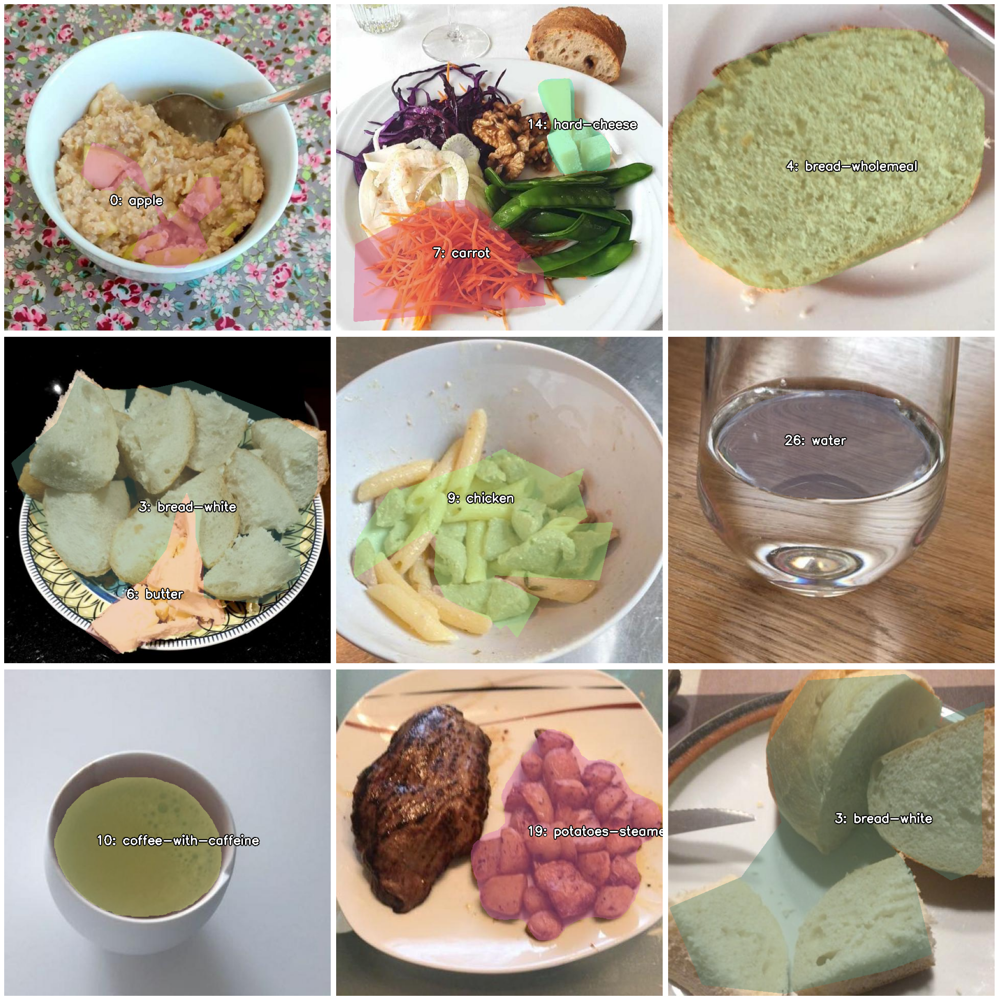

In [9]:
show_samples()

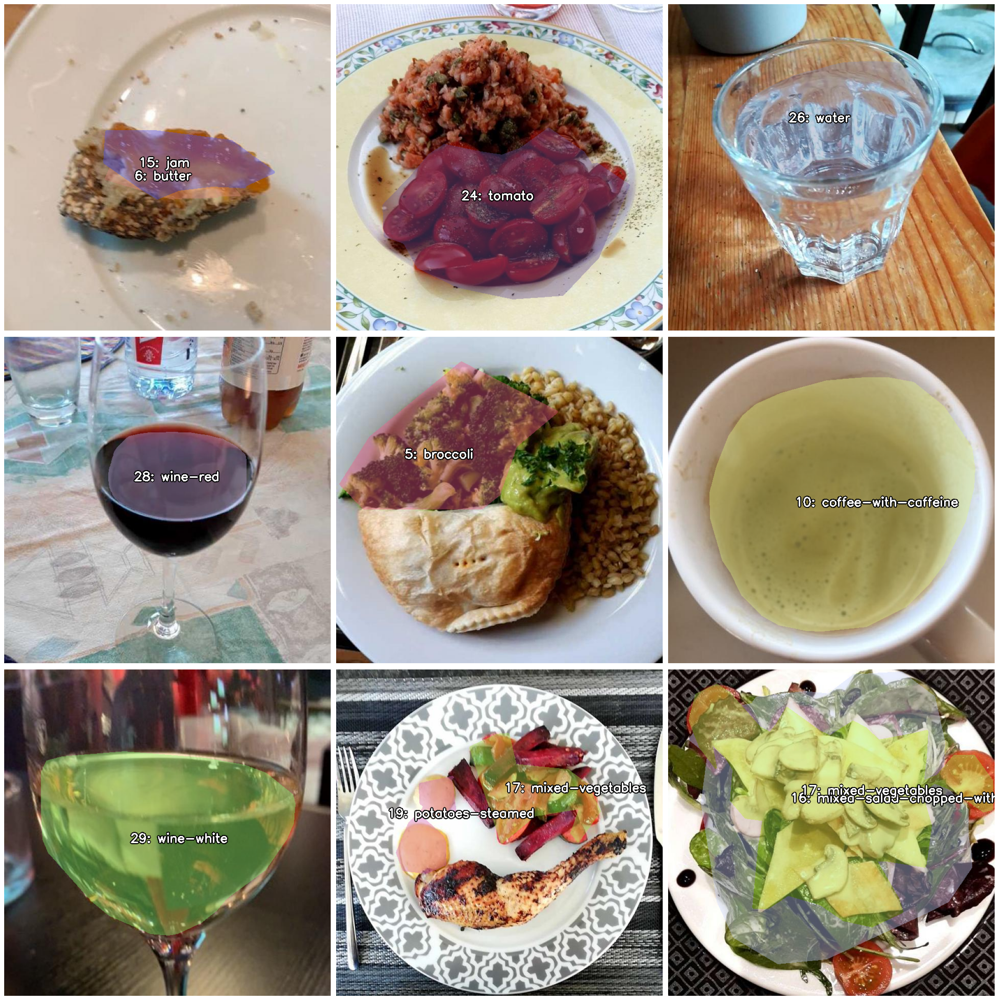

In [10]:
show_samples(split = 'valid')


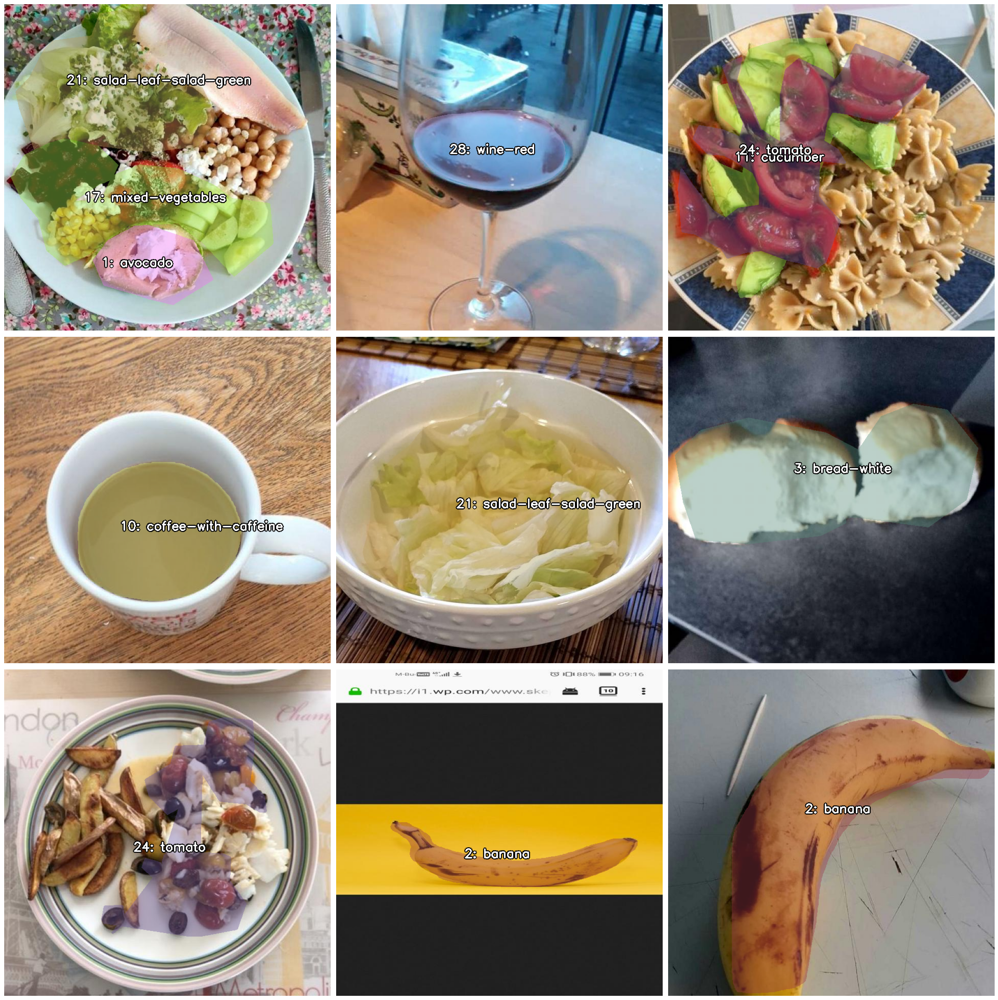

In [11]:
show_samples(split = 'test')

In [12]:

base_model = YOLO('yolo26n-seg.pt')
base_model.names

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou

In [13]:
results = base_model.train(data='/content/food-1/data.yaml' ,
                           epochs = 60 , batch = 16 , imgsz= 640 ,
                           patience=10 , exist_ok=True
                           )

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/food-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimize

In [14]:
print(f'Box MAP50: {results.box.map50}')
print(f'Box MAP70: {results.box.map75}')
print(f'Box MAP50-95: {results.box.map}\n{"-"*50}')

print(f'Mask MAP50: {results.seg.map50}')
print(f'Mask MAP70: {results.seg.map75}')
print(f'Mask MAP50-95: {results.seg.map}')

Box MAP50: 0.5924071481858029
Box MAP70: 0.5017744301900684
Box MAP50-95: 0.44025879974358323
--------------------------------------------------
Mask MAP50: 0.5456812420001881
Mask MAP70: 0.42884213308653074
Mask MAP50-95: 0.38162608133142073


In [15]:
model = YOLO('/content/runs/segment/train/weights/best.pt')


In [16]:

metrics = model.val(data='/content/food-1/data.yaml', split='test' , exist_ok=True )

print(f'\nBox MAP50: {metrics.box.map50}')
print(f'Box MAP70: {metrics.box.map75}')
print(f'Box MAP50-95: {metrics.box.map}\n{"-"*50}')

print(f'Mask MAP50: {metrics.seg.map50}')
print(f'Mask MAP70: {metrics.seg.map75}')
print(f'Mask MAP50-95: {metrics.seg.map}')

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,710,830 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1287.9±532.6 MB/s, size: 51.9 KB)
val: Scanning /content/food-1/test/labels... 916 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 916/916 1.6Kit/s 0.6s
val: New cache created: /content/food-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 58/58 4.1it/s 14.3s
                   all        916       1174      0.592      0.616      0.604      0.452       0.58      0.599      0.569      0.391
                 apple         32         32      0.943      0.875      0.906      0.827      0.966      0.875      0.906      0.876
               avocado         26         26      0.429      0.346      0.264      0.187      0.402      0.308      0.229     

# Visualizations For Train Results

In [ ]:

display(Image('/content/runs/segment/train/results.png'))

In [ ]:
display(Image('/content/runs/segment/train/confusion_matrix_normalized.png'))


#

# Visualizations For Test Results

In [ ]:
display(Image('/content/runs/segment/val/confusion_matrix_normalized.png'))


In [20]:
preds = model.predict(source = '/content/food-1/test/images', conf = 0.40 , save=True , exist_ok=True)


image 1/916 /content/food-1/test/images/006483_jpg.rf.0c5aca71beea343d6ddfb3e630d805ee.jpg: 640x640 1 salad-leaf-salad-green, 14.7ms
image 2/916 /content/food-1/test/images/006512_jpg.rf.14db8d58beaa1872f1884f11fac86c44.jpg: 640x640 1 espresso-with-caffeine, 18.2ms
image 3/916 /content/food-1/test/images/006624_jpg.rf.2b7cd8071f898034eb29afd245b356ce.jpg: 640x640 1 carrot, 14.7ms
image 4/916 /content/food-1/test/images/006639_jpg.rf.4bdfd29a6c6989e8134ad74e83b17a8a.jpg: 640x640 1 bread-white, 15.5ms
image 5/916 /content/food-1/test/images/006782_jpg.rf.3f326467b192f43289a33923fcc8339c.jpg: 640x640 (no detections), 15.7ms
image 6/916 /content/food-1/test/images/006801_jpg.rf.7e777900aa79f04d19563dad690d8e56.jpg: 640x640 1 white-coffee-with-caffeine, 14.8ms
image 7/916 /content/food-1/test/images/006959_jpg.rf.04cb1d4178c5ea5e68dd2e35cde371a0.jpg: 640x640 1 white-coffee-with-caffeine, 15.6ms
image 8/916 /content/food-1/test/images/007085_jpg.rf.c0281967dfd4336f98fb8d5727d6660e.jpg: 640x

In [ ]:
i = 0

for img in glob('/content/runs/segment/predict/*.jpg'):

  if i % 25 == 0 :
    img = cv2.imread(img)
    img = cv2.cvtColor( img , cv2.COLOR_BGR2RGB )
    plt.imshow(img)
    plt.axis('off')
    plt.show()

  i += 1